# Recurrent Neural Network Homework

In this assignment, we will implement a basic RNN network and an LSTM network with Pytorch to solve two problems. \
You will use **"Tasks"** and **"Hints"** to finish the work. **(Total 90 points)** \
You may use Machine Learning libaries like Scikit-learn for data preprocessing.

**Task Overview:**
- Implement a basic RNN network to solve time series prediction
- Implement an LSTM network to conduct sentiment analysis

## 1 - Implement a RNN model to predict time series##
### 1.1 Prepare the data (10 Points)

Prepare time series data for deep neural network training.

**Tasks:**
1. Load the given train and test data: "train.txt" and "test.txt". **(2.5 Points)**
2. Generate the **TRAIN** and **TEST** labels. **(2.5 Points)**
3. Normalize the **TRAIN** and **TEST** data with sklearn function "MinMaxScaler". **(2.5 Points)**
4. **PRINT OUT** the **TEST** data and label. **(2.5 Points)**

**Hints:**  
1. The length of original train data is 113 which starts from **"1949-01"** to **"1958-05"**. The length of original test data is 29, which starts from **"1958-07"** to **"1960-11"**.
2. Set the data types of both train and test data to "float32".
3. Use **past 12** datapoints as input data X to predict the **next 1** datapoint as Y, which is the 'next token prediction'. The time window will be 12.
4. The first 3 **TRAIN** data and label should be:

- trainX[0] = [[0.02203858 &nbsp; 0.03856748 &nbsp; 0.077135 &nbsp;  0.06887051 &nbsp; 0.04683197 &nbsp; 0.08539945 &nbsp; 0.12121212 &nbsp; 0.12121212 &nbsp; 0.08815429 &nbsp; 0.04132232 &nbsp; 0.    &nbsp; 0.03856748]]
- trainY[0] = [0.03030303]

- trianX[1] = [[0.03856748 &nbsp; 0.077135 &nbsp;  0.06887051 &nbsp; 0.04683197  &nbsp; 0.08539945  &nbsp; 0.12121212  &nbsp; 0.12121212  &nbsp; 0.08815429  &nbsp; 0.04132232  &nbsp; 0.     &nbsp;  0.03856748   &nbsp; 0.03030303]]
- trainY[1] = [0.06060606]

- trainX[2] =  [[0.077135 &nbsp;  0.06887051 &nbsp; 0.04683197 &nbsp; 0.08539945 &nbsp; 0.12121212 &nbsp; 0.12121212 &nbsp; 0.08815429 &nbsp; 0.04132232 &nbsp; 0.    &nbsp;     0.03856748 &nbsp; 0.03030303 &nbsp; 0.06060606]]
- trainY[2] = [0.10192838]

5. Apply the MinMaxScaler to both the train and test data.\
https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

In [49]:
import numpy as np
from pandas import read_csv
from sklearn.preprocessing import MinMaxScaler

# Step 1. Use pandas to read training and testing from txt file. (2.5 pts)

trainFilePath = "https://raw.githubusercontent.com/jakedog17/HW4_CAP4630/refs/heads/main/train.txt"
testFilePath = "https://raw.githubusercontent.com/jakedog17/HW4_CAP4630/refs/heads/main/test.txt"

trainDataset = read_csv(trainFilePath)
testDataset = read_csv(testFilePath)

# Step 2. Normalize training and test data into [0, 1]. (2.5 pts)
trainDataset = trainDataset["Passengers"].values.astype(np.float32).reshape(-1, 1) #sklearn needs a 2d array
testDataset = testDataset["Passengers"].values.astype(np.float32).reshape(-1, 1) #sklearn needs a 2d array

scalar = MinMaxScaler()
normalizedTrainDataset = scalar.fit_transform(trainDataset)
normalizedTestDataset = scalar.transform(testDataset)

# Step 3. Create a training and test datasets. (2.5 pts)

#train
trainX, trainY = [], []
time_window = 12
for i in range(len(normalizedTrainDataset) - time_window):
    trainX.append(normalizedTrainDataset[i:(i + time_window), 0])
    trainY.append(normalizedTrainDataset[i + time_window, 0])

trainX = np.array(trainX, dtype='float32')
trainY = np.array(trainY, dtype='float32')

#test
testX, testY = [], []
for i in range(len(normalizedTestDataset) - time_window):
    testX.append(normalizedTestDataset[i:(i + time_window), 0])
    testY.append(normalizedTestDataset[i + time_window, 0])

testX = np.array(testX, dtype='float32')
testY = np.array(testY, dtype='float32')


# Step 4. Print out the shape of data. (2.5 pts)
##print(f"trainX[0] = {trainX[0]}\ntrainY[0]={trainY[0]}")

print(f"Train X Shape: {trainX.shape}\nTrain X Shape: {trainY.shape}")
print(f"Test X Shape: {testX.shape}\nTest Y Shape: {testY.shape}")


Train X Shape: (101, 12)
Train X Shape: (101,)
Test X Shape: (17, 12)
Test Y Shape: (17,)


### 1.2 - Build the RNN model (30 Points) ##


Build a RNN model with RNN cell.

**Tasks:**
1. Build an RNN model with 1 RNN layer and 1 Linear layer, with RNN's hidden size to be 4.  **(15 Points)**
2. Initialize model, optimizer and criterion. **(7.5 Points)**
3. Train the model for **1000** epochs with **batch_size = 10** and **print out the average traning loss for every 100 epochs**. **(7.5 Points)**

**Hints:**  
1. You can use **nn.RNN** to specify RNN cells.
2. Use loss function (criterion) **MSELoss()** and select **Adam** optimizer with **learning_rate=0.005** and other default settings.

In [50]:
import torch.nn as nn

import torch.optim as optim

import torch

# Reshape tensors to 3D for PyTorch RNN: (Batch, Seq_Len, Input_Size)
trainX_tensor = torch.from_numpy(trainX).unsqueeze(-1)
trainY_tensor = torch.from_numpy(trainY).unsqueeze(-1)

testX_tensor = torch.from_numpy(testX).unsqueeze(-1)
testY_tensor = torch.from_numpy(testY).unsqueeze(-1)

# Complete the model architecture (10 pts)
class RNN(nn.Module):
  def __init__(self, input_size, hidden_size, output_size):
    super(RNN, self).__init__()
    self.hidden_size = hidden_size
    self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
    self.fc = nn.Linear(hidden_size, output_size)

  def forward(self, x):
    x, hidden = self.rnn(x)
    # keep all bacths, take the last month of the sequence (prediction), keep hidden features
    x = x[:, -1, :]

    x = self.fc(x)
    return x

# Create an instance of model, optimizer and criterion. (5 pts)
lr = 0.005
epochs = 1000
BatchSize = 10
model = RNN(1, 4, 1)

criterion = nn.MSELoss()
adamOptimizer = optim.Adam(model.parameters(), lr)


# Train the RNN Model for 1000 epoch and print out the training loss for every 100 epochs. (5 pts)
#create batches
dataset = torch.utils.data.TensorDataset(trainX_tensor, trainY_tensor)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BatchSize, shuffle=True)

#Begin Epochs
for i in range(1, epochs + 1):
  model.train()
  totalLoss = 0

  for batch_x, batch_y in dataloader:
    adamOptimizer.zero_grad()
    output = model(batch_x)
    loss = criterion(output, batch_y)
    loss.backward()

    adamOptimizer.step()

    totalLoss += loss.item() * batch_x.size(0)

  epochLoss = totalLoss/len(dataloader.dataset)

  if (i%100 == 0 and i != 0):
    print(f"Average after 100, Epoch {i}: {epochLoss}")




Average after 100, Epoch 100: 0.004729112305927394
Average after 100, Epoch 200: 0.0038488602927323466
Average after 100, Epoch 300: 0.0037385884765766117
Average after 100, Epoch 400: 0.0048190355519902445
Average after 100, Epoch 500: 0.0038619818525229776
Average after 100, Epoch 600: 0.002924294720431513
Average after 100, Epoch 700: 0.003031054981938093
Average after 100, Epoch 800: 0.004430078267405676
Average after 100, Epoch 900: 0.0023515058455453944
Average after 100, Epoch 1000: 0.0024071822777427363


### 1.3 Evaluate Predictive Model Performance (**10 Points**)

Predict datapoints with the observed datapoints and trained model.

**Tasks:**
1. Make prediction on train and test datapoints with the obtained model in section 1.2. **(2 Points)**
2. Denormalize the prediction results back to original scale with the scaler.(scaler.inverse_transform function) **(3 Points)**
3. Calculate root mean squared error (RMSE) and **print out** the error for **both TRAIN and TEST**. **(3 Points)**
4. **Plot** the **TEST** label and prediction. **(2 Points)**


**Hints:**  
1. Scale back the predictions with the build-in function "scaler.inverse_transform".\
https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html#sklearn.preprocessing.MinMaxScaler.inverse_transform
2. The plot for validation is shown below (observation test data are blue and prediction results are orange):
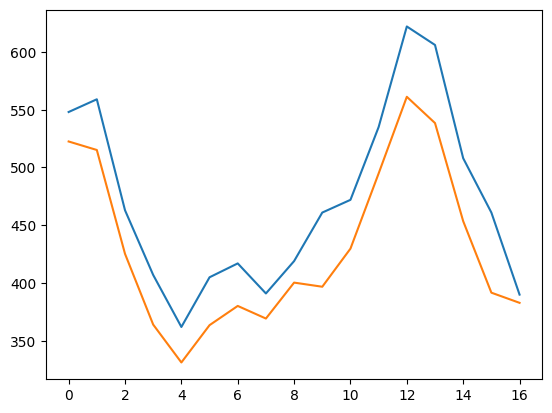

<span style="color:magenta">
    The corresponding figures could be different from the one above, but should be reasonable.**
</span>


Training Mean Squared Error (RMSE): 16.5957
Testing Mean Squared Error (RMSE): 60.0800


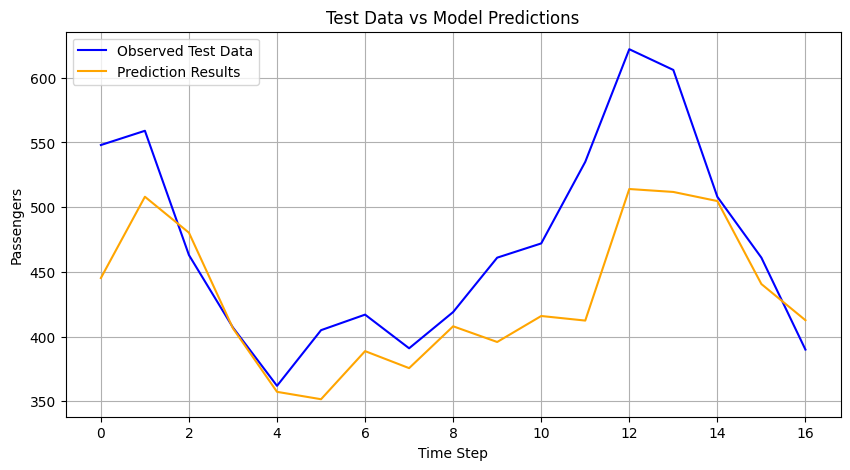

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Step 1. Inference above model on training and testing data. (2 pts)
model.eval() # Set model to evaluation mode

with torch.no_grad():
  # Forward pass on train and test features
  train_preds_scaled = model(trainX_tensor).cpu().numpy()
  test_preds_scaled = model(testX_tensor).cpu().numpy()



# Step 2. Denomalization. (3 pts)
train_preds = scalar.inverse_transform(train_preds_scaled.reshape(-1, 1))
test_preds = scalar.inverse_transform(test_preds_scaled.reshape(-1, 1))

train_y_actual = scalar.inverse_transform(trainY_tensor.numpy().reshape(-1, 1))
test_y_actual = scalar.inverse_transform(testY_tensor.numpy().reshape(-1, 1))

# Step 3. Calculate root mean squared error for training and testing and print. (3 pts)

train_rmse = np.sqrt(mean_squared_error(train_y_actual, train_preds))
test_rmse = np.sqrt(mean_squared_error(test_y_actual, test_preds))

print(f"Training Mean Squared Error (RMSE): {train_rmse:.4f}")
print(f"Testing Mean Squared Error (RMSE): {test_rmse:.4f}")

# Step 4. Plot the predictions. (2 pts)

window_to_plot = 17 #17 size

plt.figure(figsize=(10, 5))

plt.plot(test_y_actual[:window_to_plot], label='Observed Test Data', color='blue')
plt.plot(test_preds[:window_to_plot], label='Prediction Results', color='orange')
plt.title('Test Data vs Model Predictions')

plt.xlabel('Time Step')
plt.ylabel('Passengers')

plt.legend()
plt.grid(True)
plt.show()

## 2 - Use LSTM model to conduct sentiment analysis ##

### 2.1 Prepare the data (10 Points) ###
Conduct sentiment analysis using IMDB data with reccurent neural network. Make prediction on sentiment (positive/negative) as a binary classification.
More details can be found here, https://keras.io/api/datasets/imdb/

**Tasks:**
1. Load the data from IMDB review dataset and **print out** the lengths of sequences. **(5 Points)**
2. Preprocess review data to meet the network input requirement by specifying **number of words=1000**, setting **the analysis length of the review = 100**, and **padding the input sequences**. **(5 Points)**

**Hints:**  
1. You may load the IMDB data with keras.datasets.imdb.load_data(num_words=max_features). Here, max_features is set to **1000**.
2. You may use keras.preprocessing.sequence.pad_sequences(x_train, maxlen) to pad the input sequences and set maxlen to **100**.

**Note:**\
We train the build LSTM-based model with ALL training data; the **validation set** (aka **development set**) is set with the **testing set** for model evaluation. This split is common in the application with limited sampled observation data, like NLP problems.

In [28]:
import torch
import random
import numpy as np

from keras.preprocessing import sequence
from keras.datasets import imdb

# Step 1. Load IMDB dataset from keras. (5 pts)
### = imdb.load_data(###)
max_features = 1000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_features)


# Step 2. Preprocess the sequences with padding (5 pts)
maxlen = 100
x_train_pad = sequence.pad_sequences(x_train, maxlen)
x_test_pad = sequence.pad_sequences(x_test, maxlen)

### 2.2 - Design and train LSTM model (30 Points) ###

Build a LSTM model.

**Tasks:**
1. Build the LSTM model with **1 embedding layer**, **1 LSTM layer**, and **1 Linear layer**. The embedding vector is specified with the dimension of **8**. **(15 Points)**
2. Create LSTM model with **Adam** optimizer, **binary_crossentropy** loss function (BCELoss()). **(5 Points)**  
3. Train the LSTM model with **batch_size=64 for 10 epochs** and report **training and validation accuracies over epochs**. You need to use TensorDataset and DataLoader to split the data into batches with batch_size and shuffle the data. **(5 Points)**
4. **Print out** best validation accuracy. **(5 Points)**



**Hints:**  
1. Set input dimension to **1000** and output dimension to **8** for embedding layer.
2. You need to initialize hidden(h) and cell(c) for the lstm and always use h and c as input to your lstm layer. (For performance)
3. Set **hidden dimension = 8** for LSTM layer.
4. Use only the last layer as the input of linear layer (For performance)
5. Set activation function to **sigmoid** for Linear layer.
6. You may have some trouble with the data dimension, please consider using squeeze or unsqueeze to make two data have the same dimension.
7. Write a constructor with many configurations (number of layers, embedding dimension...) could save you a lot of time for the bonus questions since you can reuse the code here.

In [39]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Complete LSTM model architecture. (20 pts)
class LSTMClassifier(nn.Module):
  def __init__(self, max_features, embedding_dim, hidden_dim, num_layers):
    super(LSTMClassifier, self).__init__()
    #vars to use in forward pass
    self.num_layers = num_layers
    self.hidden_dim = hidden_dim

    self.embeddings = nn.Embedding(max_features, embedding_dim=embedding_dim)
    self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True)
    self.classifier = nn.Linear(hidden_dim, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, sentence):
    embed = self.embeddings(sentence)

    batch_size = sentence.size(0)
    #hidden
    h = torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=sentence.device)
    #cell
    c = torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=sentence.device)

    out, (hidden, cell) = self.lstm(embed, (h,c))

    #need to resize
    last_step_out = out[:, -1, :] # Shape: (64, 8)

    last_step_out = self.classifier(last_step_out)
    last_step_out = self.sigmoid(last_step_out)

    return last_step_out

# Create an instance of LSTM model, an adam optimizer and BCE loss. (5 pts)
embedding_dim = 8
hidden_dim = 8
num_layers = 1
learning_rate = 0.001
batch_size = 64
epochs = 10

model = LSTMClassifier(max_features=max_features, embedding_dim=embedding_dim, hidden_dim=hidden_dim, num_layers=num_layers)

# Adam optimizer and BCE loss function
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.BCELoss()

# Train the model, print out the loss. (5 pts)


# Convert to PyTorch Tensors and shape labels to 2D (batch_size, 1) for BCELoss
train_X_tensor = torch.tensor(x_train_pad, dtype=torch.long)
train_y_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1)

val_X_tensor = torch.tensor(x_test_pad, dtype=torch.long)
val_y_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1)

# Create TensorDatasets and DataLoaders with shuffle=True for training
train_dataset = TensorDataset(train_X_tensor, train_y_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(val_X_tensor, val_y_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# track variable for best validation accuracy
best_val_accuracy = 0

for epoch in range(1, epochs + 1):
    model.train()
    train_loss = 0.0
    correct_train = 0
    total_train = 0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()

        # Forward pass
        predictions = model(batch_x)

        # Calculate loss
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * batch_x.size(0)

        # training accuracy (threshold at 0.5 sigmoid)
        predicted_labels = (predictions >= 0.5).float()
        correct_train += (predicted_labels == batch_y).sum().item()
        total_train += batch_y.size(0)

    epoch_train_loss = train_loss / total_train
    epoch_train_acc = correct_train / total_train

    # validate model in loop
    model.eval()
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_preds = model(val_x)
            val_predicted_labels = (val_preds >= 0.5).float()

            correct_val += (val_predicted_labels == val_y).sum().item()
            total_val += val_y.size(0)

    epoch_val_acc = correct_val / total_val

    # Track best validation accuracy
    if epoch_val_acc > best_val_accuracy:
        best_val_accuracy = epoch_val_acc

    # print training and validation over epochs
    print(f"Epoch {epoch}, "f"Train Loss: {epoch_train_loss:.4f}, "f"Train Accuracy: {epoch_train_acc * 100:.2f}%, "f"Val Accuracy: {epoch_val_acc * 100:.2f}%")



# Print out the best validation accuracy. (5 pts)

print(f"\nBest Validation Accuracy: {best_val_accuracy * 100:.2f}%")

Epoch 1, Train Loss: 0.6913, Train Accuracy: 52.30%, Val Accuracy: 54.59%
Epoch 2, Train Loss: 0.6646, Train Accuracy: 59.01%, Val Accuracy: 65.32%
Epoch 3, Train Loss: 0.5991, Train Accuracy: 68.48%, Val Accuracy: 70.09%
Epoch 4, Train Loss: 0.5568, Train Accuracy: 72.12%, Val Accuracy: 71.74%
Epoch 5, Train Loss: 0.5186, Train Accuracy: 74.82%, Val Accuracy: 75.77%
Epoch 6, Train Loss: 0.4877, Train Accuracy: 76.87%, Val Accuracy: 77.54%
Epoch 7, Train Loss: 0.4592, Train Accuracy: 78.88%, Val Accuracy: 78.51%
Epoch 8, Train Loss: 0.4390, Train Accuracy: 80.07%, Val Accuracy: 79.41%
Epoch 9, Train Loss: 0.4234, Train Accuracy: 81.02%, Val Accuracy: 80.02%
Epoch 10, Train Loss: 0.4098, Train Accuracy: 81.76%, Val Accuracy: 80.77%

Best Validation Accuracy: 80.77%
